In [93]:
import numpy,pandas,json,scipy
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [94]:
# Load in data
## Data
svalbard_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="A:I").dropna(subset=["δ114Cd(‰)"])
arctic_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="K:S").dropna(subset=["δ114Cd(‰).1"])
northsea_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="U:AC").dropna(subset=["δ114Cd(‰).2"])
kheu_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="AI:AQ").dropna(subset=["δ114Cd(‰).3"])

svalbard_data["2se"] = svalbard_data["2se"]
arctic_data["2se.1"] = arctic_data["2se.1"]
northsea_data["2se.2"] = northsea_data["2se.2"]
kheu_data["2se.4"] = kheu_data["2se.4"]

# Load in GP
d114dcd_gp = GaussianProcess().fromJSON("./data/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON("./data/output/d13c_gp.json")

# Load in prior_results
with open("./data/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open("./data/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel("./data/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel("./data/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]


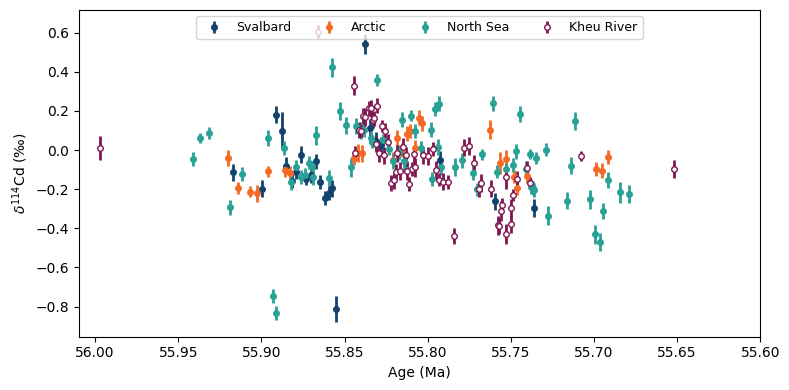

In [95]:
# Plot Data
figure,axis = pyplot.subplots(nrows=1,sharex=True,figsize=(8,4))
axes = [axis]

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",fontsize=9)

axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")
axes[0].set_xlim((56.01,55.60))

# Add labels
axes[0].set_xlabel("Age (Ma)")

figure.tight_layout()
figure.savefig("./figures/cadmium_data.png",transparent=True)


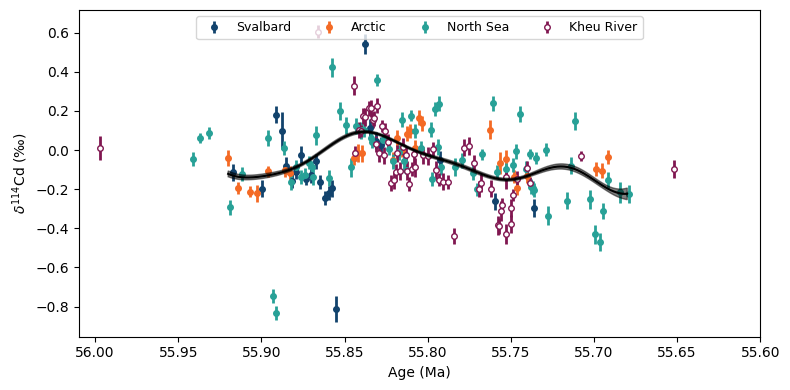

In [96]:
# Plot
figure

d114dcd_gp.plotMean(group=-1,color="black",axis=axes[0])
d114dcd_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")

# axes[0].invert_xaxis()

figure.tight_layout()
figure.savefig("./figures/cadmium_data_gp.png",transparent=True)


figure

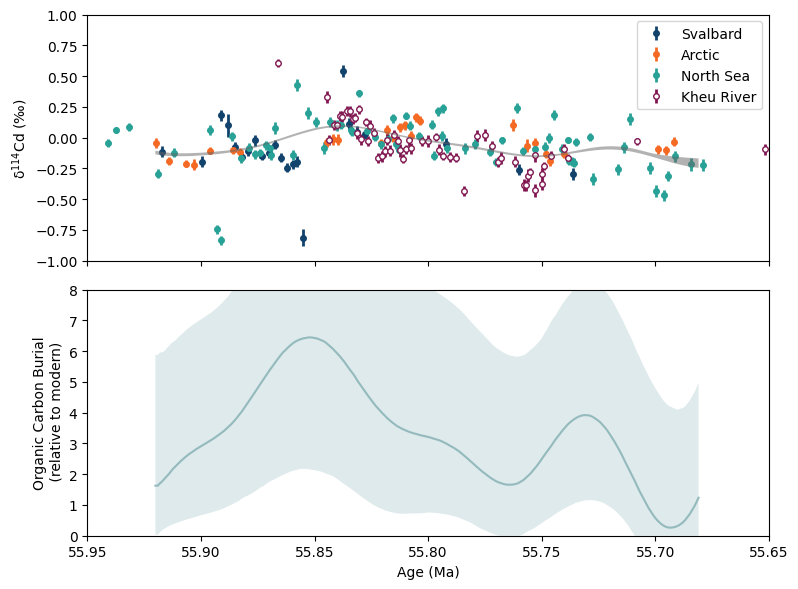

In [97]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True,figsize=(8,6))

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-1.0,1.0))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(prior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#94babd",
                                                         alpha=0.3)
axes[1].add_patch(organic_prior_patch)
axes[1].plot(time,prior_metrics["organic_flux_median"]/5287500,color="#94babd",linestyle="-")

axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,8.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to modern)")

figure.tight_layout()
figure.savefig("./figures/cadmium_prior.png",transparent=True)

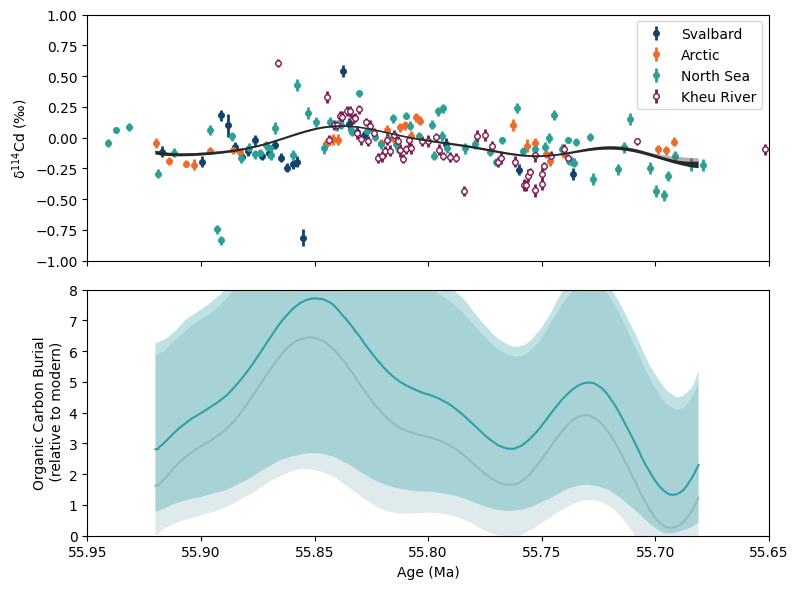

In [98]:
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)


organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#2ea0a8",
                                                                alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time,posterior_metrics["organic_flux_median"]/5287500,color="#2ea0a8",linestyle="-")

figure.savefig("./figures/cadmium_posterior.png",transparent=True)
figure




Text(0, 0.5, 'Organic Carbon Burial\n (relative to modern)')

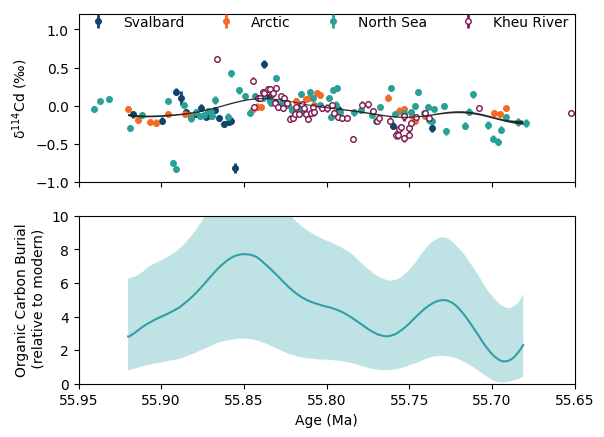

In [99]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",bbox_to_anchor=(0,0.07,1,1),frameon=False)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"][0:]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][0:][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)

axes[0].set_ylim((-1.0,1.2))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"][0:]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][0:][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#2ea0a8",
                                                                alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time,posterior_metrics["organic_flux_median"][0:]/5287500,color="#2ea0a8",linestyle="-")


axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,10.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to modern)")

# figure.tight_layout()
# figure.savefig("./figures/cadmium_prior.png",transparent=True)


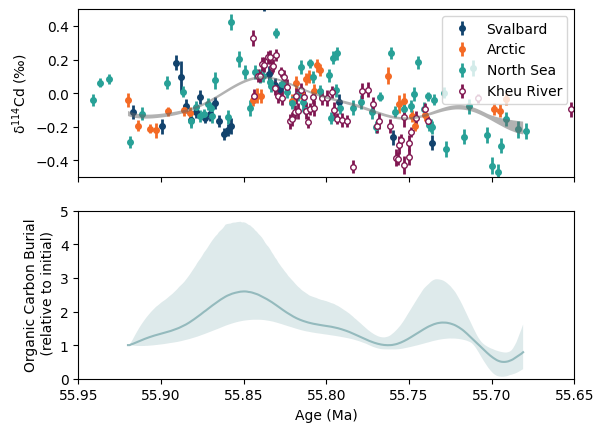

In [100]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True)
common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])


# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-0.5,0.5))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][::-1])))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#94babd",
                                                         alpha=0.3)
axes[1].add_patch(organic_prior_patch)
axes[1].plot(time,posterior_metrics["relative_organic_flux_median"],color="#94babd",linestyle="-")

axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,5.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to initial)")

pyplot.show()

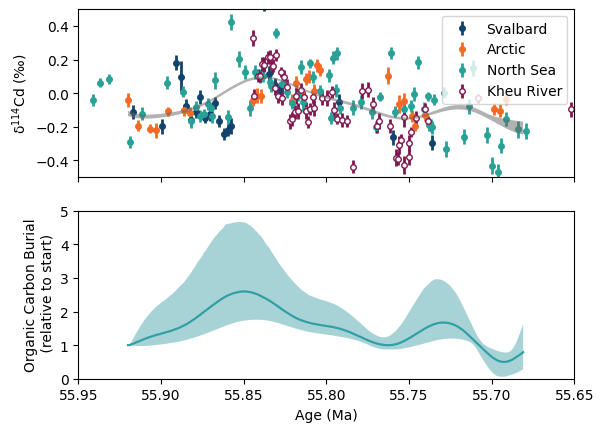

In [101]:
# Second subplot
organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"][0:]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][0:][::-1])))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                    organic_posterior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#2ea0a8",
                                                         alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time,posterior_metrics["relative_organic_flux_median"][0:],color="#2ea0a8",linestyle="-")

axes[1].set_ylim((0.0,5.0))
axes[1].set_ylabel("Organic Carbon Burial\n (relative to start)")
axes[1].set_xlabel("Age (Ma)")


figure


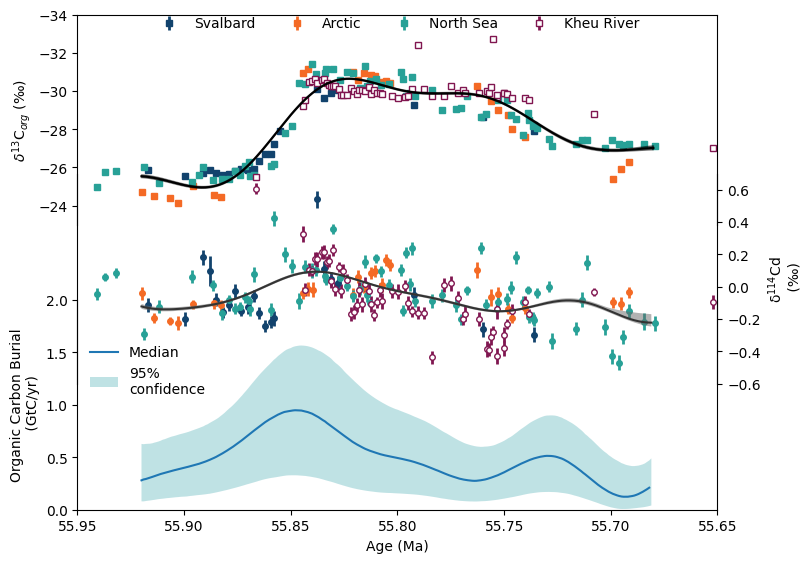

In [102]:

time_step_length = (time[1]-time[0])*posterior_results[0]["time_multiplier"]

subset_start = 0
subset_end = -1

subset_time = time[subset_start:subset_end]

carbon_over_cadmium = (100/1e3)/5287500  # GtC/mol organic

flux_multipliers = [numpy.cumprod(1.0+numpy.array(model["flux_multiplier"])) for model in posterior_results]
inverse_flux_multipliers = [1.0/flux_multiplier for flux_multiplier in flux_multipliers]

## Relative
relative_organic_burials = [numpy.array(model["organic_mass"])/model["organic_mass"][0] for model in posterior_results]

# Constant stoichiometry
# Total
organic_burial_constant = [numpy.array(model["organic_mass"])
                                                            *time_step_length
                                                            *carbon_over_cadmium for model in posterior_results]
total_organic_burial_constant = [numpy.sum(organic_burial) for organic_burial in organic_burial_constant]
# Excess
excess_organic_burial_constant = [(numpy.array(model["organic_mass"])-model["organic_mass"][subset_start])
                                                *time_step_length
                                                *carbon_over_cadmium for model in posterior_results]
total_excess_organic_burial_constant = [numpy.sum(excess_organic_burial) for excess_organic_burial in excess_organic_burial_constant]

# Variable stoichiometry
# Total
organic_burial_variables = [numpy.array(model["organic_mass"])
                                                            *time_step_length
                                                            /flux_multiplier[subset_start:subset_end]
                                                            *carbon_over_cadmium for model,flux_multiplier in zip(posterior_results,flux_multipliers)]
total_organic_burial_variable = [numpy.sum(organic_burial) for organic_burial in organic_burial_variables]

organic_burial_variable_per_year = [organic_burial/time_step_length for organic_burial in organic_burial_variables]

# Excess
excess_organic_burial_variables = [(numpy.array(model["organic_mass"])-model["organic_mass"][subset_start])
                                                *time_step_length
                                                /flux_multiplier[subset_start:subset_end]
                                                *carbon_over_cadmium for model,flux_multiplier in zip(posterior_results,flux_multipliers)]
total_excess_organic_burial_variable = [numpy.sum(excess_organic_burial) for excess_organic_burial in excess_organic_burial_variables]
excess_organic_burial_variable_per_year = [excess_organic_burial/time_step_length for excess_organic_burial in excess_organic_burial_variables]


# Plot
figure,axes = pyplot.subplots(nrows=3,figsize=(8,6))
common_attributes = {"fmt":'s',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ13Corg(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ13Corg(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ13Corg(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ13Corg(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='s',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

d13C_gp.plotMean(group=-1,color="black",axis=axes[0])
d13C_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

axes[0].set_ylabel("$\\delta^{13}$C$_{org}$ (‰)")
axes[0].set_ylim((-23,-34))

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",bbox_to_anchor=(0,0.05,1,1),frameon=False)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

handle_0 = axes[1].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[1].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[1].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[1].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)



# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[1].add_patch(d114Cd_prior_patch)
axes[1].plot(time,posterior_metrics["seawater_d114Cd_median"],color="#333333",linestyle="-")

axes[1].set_ylim((-0.6,0.7))
axes[1].set_ylabel("δ$^{114}$Cd\n (‰)")

# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.percentile(organic_burial_variable_per_year,2.5,axis=0),
                                    numpy.percentile(organic_burial_variable_per_year,97.5,axis=0)[::-1]))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#2ea0a8",
                                                         alpha=0.3)
axes[2].plot(subset_time,numpy.median(organic_burial_variable_per_year,axis=0)[1:])
axes[2].add_patch(organic_prior_patch)
# axes[1].plot(time,posterior_metrics["relative_organic_flux_median"],color="#d97979",linestyle="-")

axes[2].set_xlim((55.95,55.65))
axes[2].set_ylim((0.0,2.0))

axes[2].set_ylabel("Organic Carbon Burial\n (GtC/yr)")

axes[2].legend(["Median","95%\nconfidence"],loc="center left",bbox_to_anchor=(0,0.16,1,1),frameon=False)


axes[2].set_xlabel("Age (Ma)")

# Move the axes to overlap
axes_height = 0.35
axes_width = 0.8
axes[0].set_position([0.125,0.575,axes_width,axes_height])
axes[1].set_position([0.125,0.31,axes_width,axes_height])
axes[2].set_position([0.125,0.1,axes_width,axes_height])

# Move middle y axis to right
axes[1].yaxis.tick_right()
axes[1].yaxis.set_label_position("right")

for axis in axes:
    axis.set_facecolor("none")
    axis.spines['top'].set_visible(False)
    axis.spines['bottom'].set_visible(False)
    axis.set_xlim((55.95,55.65))
for axis in axes[:-1]:
    axis.get_xaxis().set_ticks([])
axes[0].spines['top'].set_visible(True)
axes[-1].spines['bottom'].set_visible(True)

figure.savefig("./figures/carbon_cadmium_burial.pdf",transparent=True)

pyplot.show()

[1.2596872384518478, 2.893129627537805, 2.1930266036858095, 0.3522270663430501, 0.7098419046408624, 2.3113072788240716, 0.557724950857089, 1.2977731901965193, 2.1429017057362314, 1.7517988331260326, 2.642631193415989, 2.4719597346185727, 2.5176122631529605, 2.554425497198646, 2.218011888945839, 1.2328479981855298, 1.1702087267094137, 2.776232168762526, 2.2271761820826885, 2.344627847097887, 2.4417829738663706, 0.7792205088533641, 2.9028941821572487, 1.4411980102343829, 2.7916896480834805, 1.4734123941724706, 2.9058342686634924, 0.6959169613861416, 2.131578804276197, 0.8870967458626575, 2.9949426621156605, 1.3585706732216287, 1.236679916288901, 0.7032912478544785, 2.557391277270784, 1.7312512929425539, 2.69719281991825, 1.2091007235637141, 1.1840356217335757, 2.427490407247865, 0.37127345662856004, 2.6363792027291826, 2.5144268153469556, 2.43743333855056, 2.8885658937074563, 1.7583317754866052, 2.3912635214076317, 0.4690669859442804, 1.238747092265205, 1.4538478632604195, 1.557441294787

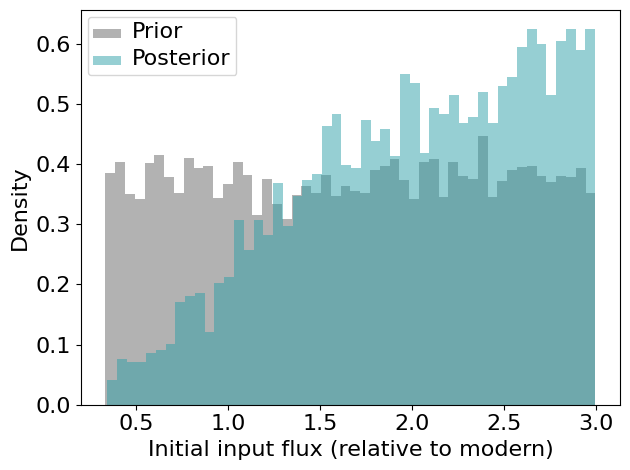

In [103]:
original_input_isotopes = json.load(open('./data/output/original_initial_conditions.json','r'))['input_multiplier']
prior_initial_input_isotopes = numpy.array([model["input_mass"][0]/30000000.0 for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_mass"][0]/30000000.0 for model in posterior_results])

print(original_input_isotopes)

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=50,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Initial input flux (relative to modern)")
axes.set_ylabel("Density")

axes.legend(["Prior","Posterior"])
# # Legend
# axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("./figures/cadmium_initial_input_flux.png",transparent=True)

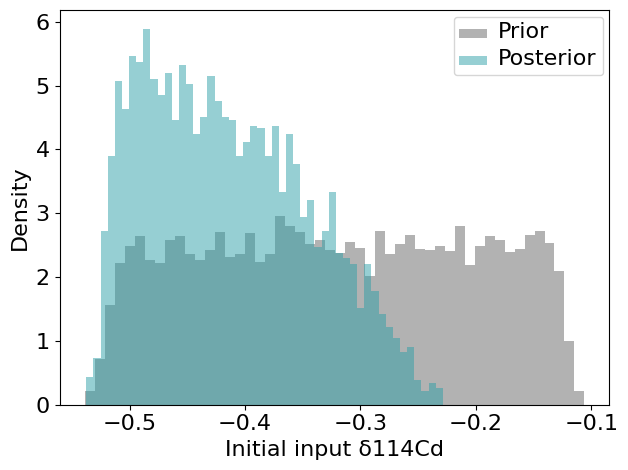

In [104]:
original_input_isotopes = json.load(open('./data/output/original_initial_conditions.json','r'))['input_isotopes']
prior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=100,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Initial input δ114Cd")
axes.set_ylabel("Density")

# # Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("./figures/cadmium_initial_input_isotopes.png",transparent=True)

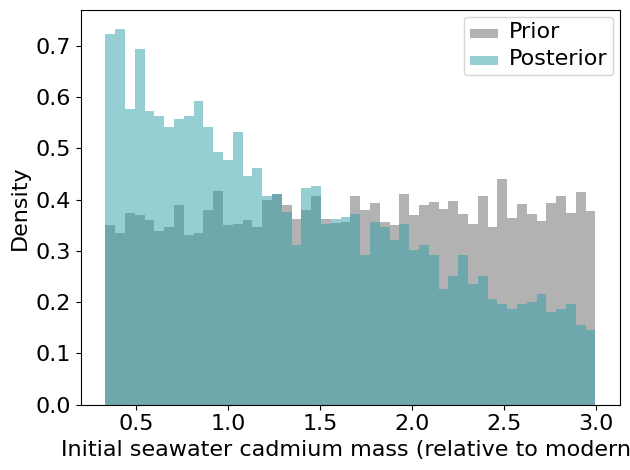

In [105]:
original_seawater_mass = json.load(open('./data/output/original_initial_conditions.json','r'))['mass_multiplier']
prior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in prior_results])
posterior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_seawater_mass,bins=50,color="#666666",alpha=0.5,density=True)
# axes.hist(prior_initial_seawater_mass,bins=20,color="#94babd",alpha=0.3)
axes.hist(posterior_initial_seawater_mass,bins=50,color="#2ea0a8",alpha=0.5,density=True)


axes.set_xlabel("Initial seawater cadmium mass (relative to modern)")
axes.set_ylabel("Density")

# Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("./figures/cadmium_initial_seawater_mass.png",transparent=True)